In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
sales_data = pd.read_csv('BigMart Sales Data.csv')

In [3]:
# Display the first few rows of the dataset
print(sales_data.head())

  Item_Identifier  Item_Weight Item_Fat_Content  Item_Visibility  \
0           FDA15         9.30          Low Fat         0.016047   
1           DRC01         5.92          Regular         0.019278   
2           FDN15        17.50          Low Fat         0.016760   
3           FDX07        19.20          Regular         0.000000   
4           NCD19         8.93          Low Fat         0.000000   

               Item_Type  Item_MRP Outlet_Identifier  \
0                  Dairy  249.8092            OUT049   
1            Soft Drinks   48.2692            OUT018   
2                   Meat  141.6180            OUT049   
3  Fruits and Vegetables  182.0950            OUT010   
4              Household   53.8614            OUT013   

   Outlet_Establishment_Year Outlet_Size Outlet_Location_Type  \
0                       1999      Medium               Tier 1   
1                       2009      Medium               Tier 3   
2                       1999      Medium               Tier

# Data Preprocessing

In [4]:
# Handle missing values (if any)
sales_data.fillna(method='ffill', inplace=True)

In [5]:
# Encode categorical variables
sales_data = pd.get_dummies(sales_data, drop_first=True)

# Display the first few rows of the dataset
print(sales_data.head())

# Display the column names of the dataset
print(sales_data.columns)

   Item_Weight  Item_Visibility  Item_MRP  Outlet_Establishment_Year  \
0         9.30         0.016047  249.8092                       1999   
1         5.92         0.019278   48.2692                       2009   
2        17.50         0.016760  141.6180                       1999   
3        19.20         0.000000  182.0950                       1998   
4         8.93         0.000000   53.8614                       1987   

   Item_Outlet_Sales  Item_Identifier_DRA24  Item_Identifier_DRA59  \
0          3735.1380                      0                      0   
1           443.4228                      0                      0   
2          2097.2700                      0                      0   
3           732.3800                      0                      0   
4           994.7052                      0                      0   

   Item_Identifier_DRB01  Item_Identifier_DRB13  Item_Identifier_DRB24  ...  \
0                      0                      0                    

In [6]:
# Split data into features and target
X = sales_data.drop('Item_Outlet_Sales', axis=1)
y = sales_data['Item_Outlet_Sales']

In [7]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
# Train Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

In [9]:
# Evaluate Linear Regression Model
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_r2 = r2_score(y_test, lr_predictions)

print(f'Linear Regression RMSE: {lr_rmse}')
print(f'Linear Regression MAE: {lr_mae}')
print(f'Linear Regression R²: {lr_r2}')

Linear Regression RMSE: 152441314264.88065
Linear Regression MAE: 9643335597.176836
Linear Regression R²: -8549893385592272.0


In [10]:
# Train Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

In [11]:
# Evaluate Random Forest Regressor
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)

print(f'Random Forest RMSE: {rf_rmse}')
print(f'Random Forest MAE: {rf_mae}')
print(f'Random Forest R²: {rf_r2}')

Random Forest RMSE: 1091.4224962935111
Random Forest MAE: 760.0032688129032
Random Forest R²: 0.5617306165191339


In [12]:
# Cross-validation for Random Forest Regressor
rf_cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='r2')
print(f'Random Forest Cross-Validation R² Scores: {rf_cv_scores}')
print(f'Random Forest Cross-Validation Mean R² Score: {np.mean(rf_cv_scores)}')

Random Forest Cross-Validation R² Scores: [0.56794984 0.52063123 0.51833896 0.56257429 0.56498505]
Random Forest Cross-Validation Mean R² Score: 0.5468958731675722


In [13]:
# Feature Importance
feature_importances = pd.DataFrame(rf_model.feature_importances_, index=X.columns, columns=['Importance']).sort_values('Importance', ascending=False)
print(feature_importances)

                                 Importance
Item_MRP                       3.949001e-01
Outlet_Type_Supermarket Type1  9.582286e-02
Outlet_Identifier_OUT027       6.494041e-02
Item_Visibility                5.660457e-02
Outlet_Type_Supermarket Type3  4.300544e-02
...                                     ...
Item_Identifier_DRL59          9.141461e-09
Item_Identifier_FDM16          0.000000e+00
Item_Identifier_FDK57          0.000000e+00
Item_Identifier_FDT38          0.000000e+00
Item_Identifier_FDN52          0.000000e+00

[1597 rows x 1 columns]


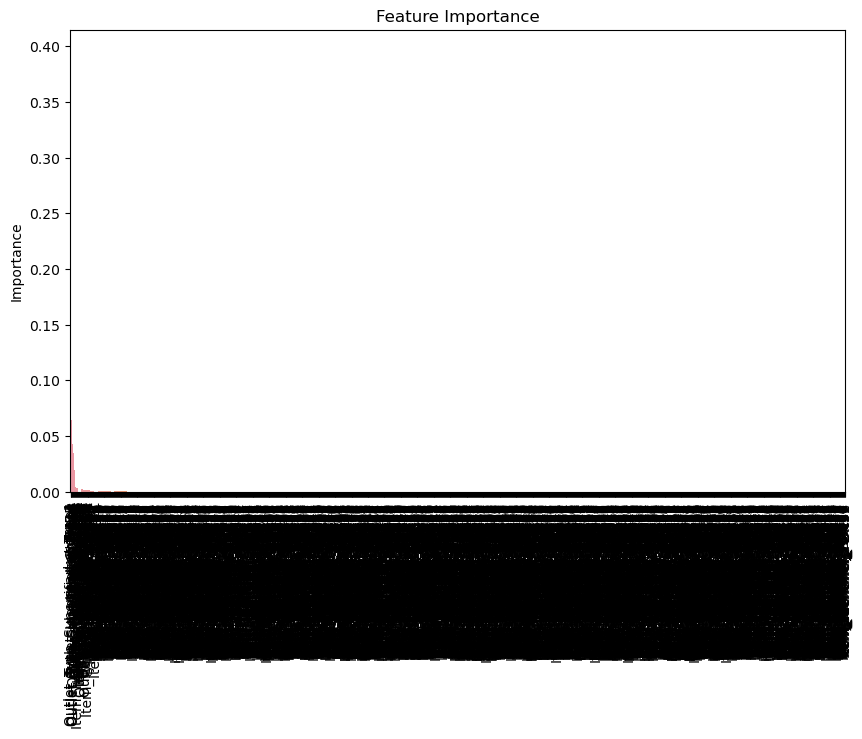

In [14]:
# Plotting Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.index, y=feature_importances['Importance'])
plt.title('Feature Importance')
plt.xticks(rotation=90)
plt.show()

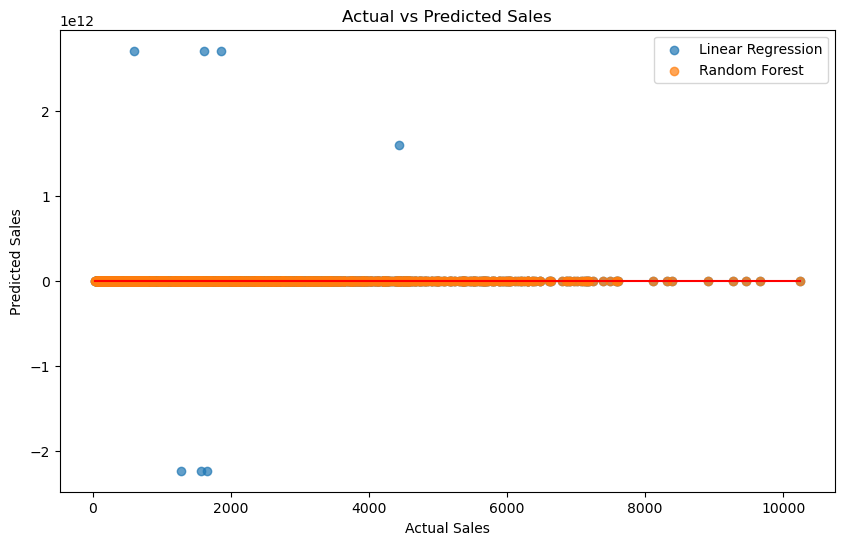

In [15]:
# Plotting Predictions vs Actual
plt.figure(figsize=(10, 6))
plt.scatter(y_test, lr_predictions, label='Linear Regression', alpha=0.7)
plt.scatter(y_test, rf_predictions, label='Random Forest', alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.legend()
plt.show()

In [16]:
# Save the predictions to a new CSV file
predictions = pd.DataFrame({
    'Actual': y_test,
    'LR_Predicted': lr_predictions,
    'RF_Predicted': rf_predictions
})
predictions.to_csv('sales_predictions.csv', index=False)